<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/4_5_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
%%writefile laplacian.cpp
#include <opencv2/opencv.hpp>
#include <iostream>

using namespace cv;
using namespace std;

int main(int argc, char** argv) {
    if (argc != 2) {
        cout << "Kullanım: ./laplacian_program <gorsel_adi.jpg>" << endl;
        return -1;
    }

    // 1. Görüntüyü gri tonlamalı oku
    Mat image = imread(argv[1], IMREAD_GRAYSCALE);
    if (image.empty()) {
        cout << "HATA: Görüntü okunamadı! Lütfen dosya adını kontrol edin." << endl;
        return -1;
    }

    // 2. Gauss Filtresi ile yumuşatma (Gürültüyü engellemek için)
    Mat blurred_image;
    GaussianBlur(image, blurred_image, Size(3, 3), 0, 0);

    // 3. Laplacian Filtresini Uygula (3x3 çekirdek)
    Mat laplacian_result, abs_laplacian;
    Laplacian(blurred_image, laplacian_result, CV_32F, 3);

    // Görüntülenebilir 8-bit formata çevir
    convertScaleAbs(laplacian_result, abs_laplacian);

    // 4. Sonucu kaydet
    imwrite("laplacian_sonuc.jpg", abs_laplacian);

    cout << "BAŞARILI: Gauss ve Laplacian uygulandı, 'laplacian_sonuc.jpg' kaydedildi!" << endl;
    return 0;
}

Overwriting laplacian.cpp


In [8]:
# OpenCV kütüphanelerinin kurulu olduğundan emin ol
!apt-get -q -y install libopencv-dev

# Kodu derle
!g++ laplacian.cpp -o laplacian_program `pkg-config --cflags --libs opencv4`

# Programı çalıştırarak görseli işle
!./laplacian_program "test"

Reading package lists...
Building dependency tree...
Reading state information...
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
BAŞARILI: Gauss ve Laplacian uygulandı, 'laplacian_sonuc.jpg' kaydedildi!


<Figure size 640x480 with 0 Axes>

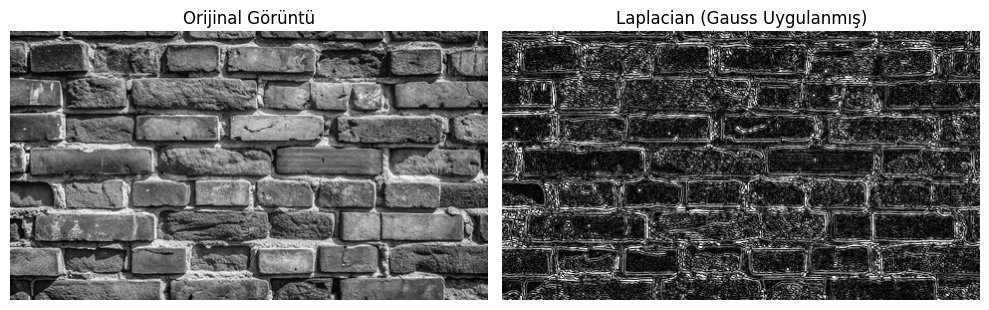

In [9]:
import cv2
import matplotlib.pyplot as plt
import os

# Dosya yollarını belirle
orijinal_yol = 'test'
laplacian_yol = 'laplacian_sonuc.jpg'

# Dosyaların var olduğundan emin ol ve oku
if os.path.exists(orijinal_yol) and os.path.exists(laplacian_yol):
    orijinal = cv2.imread(orijinal_yol, cv2.IMREAD_GRAYSCALE)
    laplacian = cv2.imread(laplacian_yol, cv2.IMREAD_GRAYSCALE)

    # Görüntülerin başarıyla (None olmadan) okunup okunmadığını kontrol et
    if orijinal is not None and laplacian is not None:
        # Eski çizimleri temizle (Bellek sorunu yaşamamak için)
        plt.clf()
        plt.figure(figsize=(10, 5))

        plt.subplot(1, 2, 1)
        plt.imshow(orijinal, cmap='gray')
        plt.title('Orijinal Görüntü')
        plt.axis('off')

        plt.subplot(1, 2, 2)
        plt.imshow(laplacian, cmap='gray')
        plt.title('Laplacian (Gauss Uygulanmış)')
        plt.axis('off')

        plt.tight_layout()
        plt.show()
    else:
        print("HATA: Dosyalar dizinde var ancak resim olarak okunamıyor. C++ kodunuzu tekrar çalıştırıp görseli yeniden oluşturun.")
else:
    print("HATA: 'test' veya 'laplacian_sonuc.jpg' dosyası bulunamadı. Lütfen sol paneli kontrol edin.")